## Theoretical minimum 
### memmory bounds for decision trees and fast odts





# Tree Structures: Node Count, Memory Requirements, and Training Data Considerations

This section outlines the structural and computational properties of decision trees, focusing on node count, memory footprint, and training data requirements. Particular emphasis is given to traditional decision trees and Fast ODTs.

---

## 1. Minimum Structure of Decision Trees

A standard decision tree develops `M` nodes according to the following equation:

```
M = 2^(n + 1) - 1
```

Where:

* `n` denotes the number of splits (internal decision points),
* `M` is the total number of nodes in the tree.

Each node in a traditional decision tree typically stores a minimal set of data (e.g., a decision rule or threshold).

Fast ODTs in contrast, store additional statistical information at each node to support incremental learning via the Hoeffding bound.



### Number of nodes for DTs 

In case of standard DTs we can assume that each node stores one value which can be 32 or 64 bits

/tmp/ipykernel_82828/3879308048.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


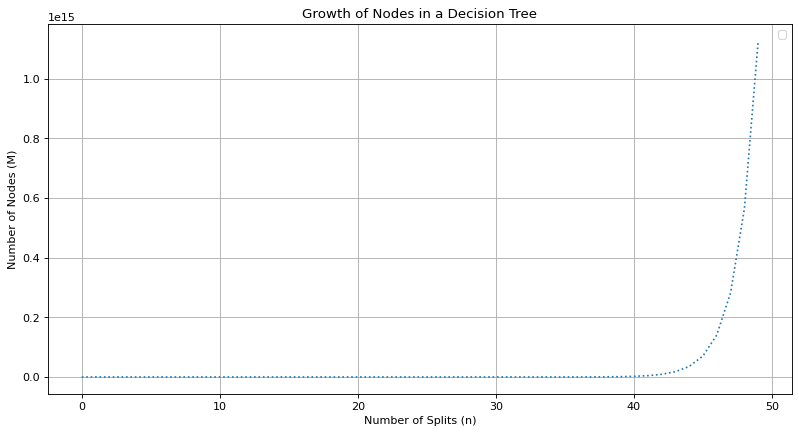

In [70]:
import matplotlib.pyplot as plt
import numpy as np

def M(n):
    return 2**(n + 1) - 1

number_of_splits = np.arange(0,50)
number_of_nodes = M(number_of_splits)


plt.figure(figsize=(12, 6), dpi=80)
plt.plot(number_of_splits, number_of_nodes, linestyle=':')
plt.xlabel("Number of Splits (n)")
plt.ylabel("Number of Nodes (M)")
plt.title("Growth of Nodes in a Decision Tree")
plt.grid(True)
plt.legend()
plt.show()



## 2. Additional Statistics in Fast ODTs

Each node in a Fast ODT maintains statistics required for evaluating and selecting splits based on partial, incrementally observed data.

### 2.1 Feature-Level Statistics

* `Sum_x`: Cumulative sum of observed feature values.
* `last_observed_value`: Most recent value observed for the feature.

### 2.2 Split Candidate Statistics (per potential child node: left and right)

* `2 × sum(y)`: Sum of target values observed on each side.
* `2 × sum(y²)`: Sum of squared target values observed on each side.
* `2 × count`: Number of samples observed on each side.

These statistics are used to compute gain estimates and assess the quality of potential splits.



## 3. Theoretical Memory Footprint per Node

The total theoretical memory cost per node, given `u` features, is expressed as:

```
H(u) = 3 × basic_statistics 
       + u × (2 × basic_feature_statistics 
       + 2 × (3 × statistics_for_potential_split))
```

Where:

* `u` is the number of input features,
* `basic_statistics` includes quantities such as class counts or entropy measures,
* `basic_feature_statistics` refers to per-feature aggregates (e.g., `Sum_x`),
* `statistics_for_potential_split` includes sufficient statistics needed for evaluating split quality (as listed above).

(50,)
(50,)
(50,)
(50,)
(50,)


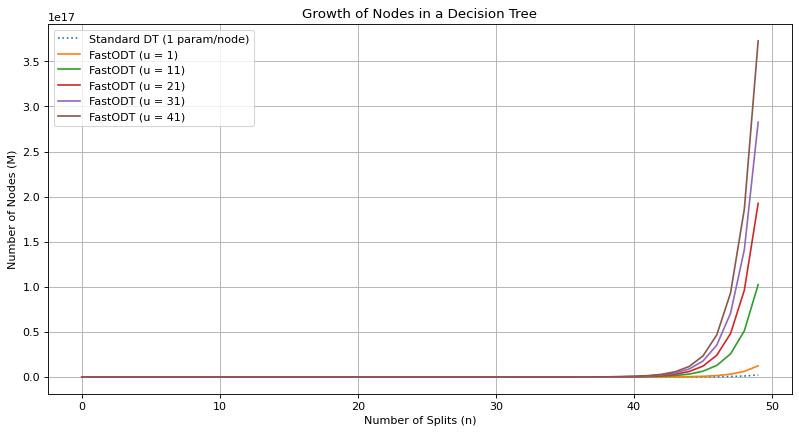

In [71]:
import matplotlib.pyplot as plt
import numpy as np

def M(n):
    n = n.astype(np.float64)
    return 2**(n + 1) - 1

def H(u):
    return (3 + u * 8)

def HM(n,u):
    return H(u).reshape(u.shape[0], 1) * M(n).reshape(1, n.shape[0])


dts_params = 2

number_of_splits = np.arange(0,50)
number_of_nodes = M(number_of_splits)
dts_memory_bound = number_of_nodes * dts_params

features = np.arange(1,50,10)
fodt_memory_bounds = HM(number_of_splits,features)

plt.figure(figsize=(12, 6), dpi=80)
plt.plot(number_of_splits, dts_memory_bound, linestyle=':', label="Standard DT (1 param/node)")

for n, fodt_memory_bound in enumerate(fodt_memory_bounds):
    print(fodt_memory_bound.shape)
    plt.plot(number_of_splits,fodt_memory_bound, linestyle='-', label=f"FastODT (u = {features[n]})")

plt.xlabel("Number of Splits (n)")
plt.ylabel("Number of Nodes (M)")
plt.title("Growth of Nodes in a Decision Tree")
plt.grid(True)
plt.legend()
plt.show()


## 4. Training Data Requirements

### 4.1 Standard Decision Trees

Traditional decision trees require access to the **entire training dataset** during the training phase. Consequently, memory usage increases **linearly** with the dataset size.

### 4.2 Fast ODTs

Fast ODTs operate in a **streaming setting** and support **incremental learning**. They process data **one instance at a time** and do not require storage of historical data for further training. This property makes them particularly suitable for large-scale and evolving datasets where retaining the entire dataset is impractical.


(3, 50) (3, 50) (50,)


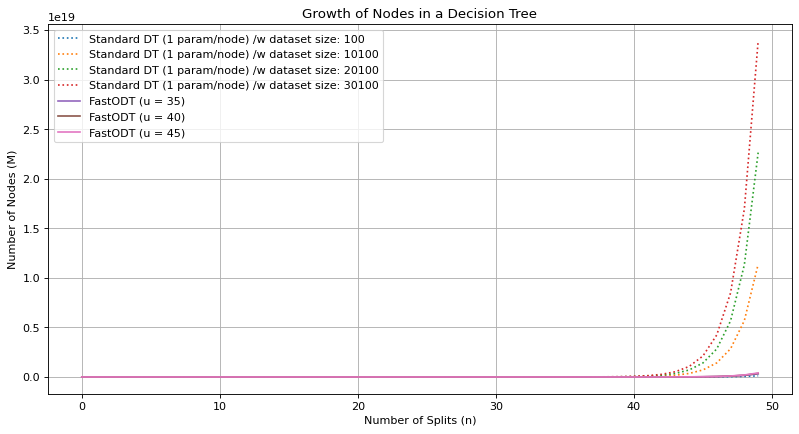

In [76]:
import matplotlib.pyplot as plt
import numpy as np

def M(n):
    n = n.astype(np.float64)
    return 2**(n + 1) - 1

def H(n,u):
    return 3 + u.reshape(u.shape[0], 1) * 8 * M(n).reshape(1, n.shape[0])

datasets_sizes = np.arange(100,40000,10000)
dts_params = 1

number_of_splits = np.arange(0,50)
number_of_nodes = M(number_of_splits)
dts_memory_bound = number_of_nodes * dts_params

features = np.arange(35,50,5)
fodt_params = H(number_of_splits,features)
fodt_memory_bounds = fodt_params
print(fodt_params.shape,fodt_memory_bounds.shape,dts_memory_bound.shape)


plt.figure(figsize=(12, 6), dpi=80)
for dataset_size in datasets_sizes:
    plt.plot(number_of_splits,dts_memory_bound * dataset_size, linestyle=':', label=f"Standard DT (1 param/node) /w dataset size: {dataset_size}")

for n, fodt_memory_bound in enumerate(fodt_memory_bounds):
    plt.plot(number_of_splits,fodt_memory_bound, linestyle='-',label=f"FastODT (u = {features[n]})")

plt.xlabel("Number of Splits (n)")
plt.ylabel("Number of Nodes (M)")
plt.title("Growth of Nodes in a Decision Tree")
plt.grid(True)
plt.legend()
plt.show()
